<a href="https://colab.research.google.com/github/ADII56-23/dmpm-lab/blob/main/dmpm08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Implement K-mean and K-medoid


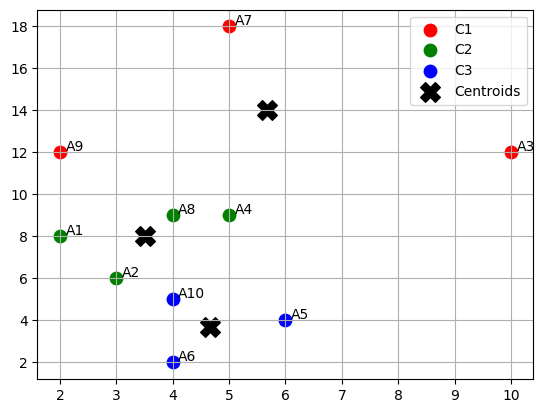

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 10 Data Points
data = {'A1':[2,8], 'A2':[3,6], 'A3':[10,12], 'A4':[5,9], 'A5':[6,4], 'A6':[4,2], 'A7':[5,18], 'A8':[4,9], 'A9':[2,12], 'A10':[4,5]}
X = np.array(list(data.values()))

def kmeans(X, k=3, iters=10):
    np.random.seed(42)
    centroids = X[np.random.choice(len(X), k, replace=False)]
    for _ in range(iters):
        # Assign clusters & update centroids
        clusters = np.argmin(np.linalg.norm(X[:, None] - centroids, axis=2), axis=1)
        new_centroids = np.array([X[clusters == j].mean(axis=0) if np.any(clusters == j) else centroids[j] for j in range(k)])
        if np.all(centroids == new_centroids): break
        centroids = new_centroids
    return centroids, clusters

centroids, clusters = kmeans(X, k=3)


colors = ['r', 'g', 'b']
for j in range(3):
    plt.scatter(X[clusters == j, 0], X[clusters == j, 1], s=80, c=colors[j], label=f'C{j+1}')
plt.scatter(centroids[:, 0], centroids[:, 1], s=200, c='black', marker='X', label='Centroids')
for i, txt in enumerate(data.keys()):
    plt.annotate(txt, (X[i,0]+0.1, X[i,1]+0.1))
plt.legend(); plt.grid(True); plt.show()

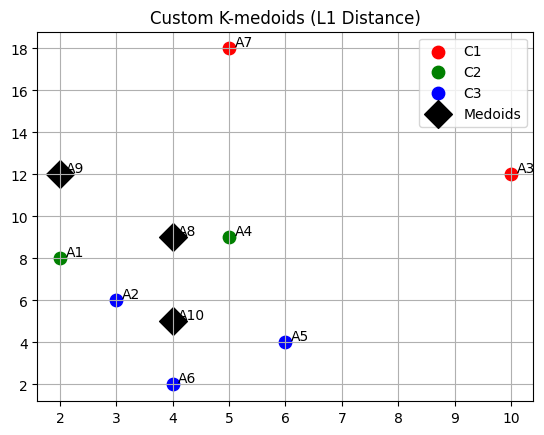

In [ ]:
def kmedoids(X, k=3, iters=10):
    np.random.seed(42)

    medoids = X[np.random.choice(len(X), k, replace=False)]

    for _ in range(iters):

        clusters = np.argmin(np.sum(np.abs(X[:, None] - medoids), axis=2), axis=1)


        new_medoids = []
        for j in range(k):
            cluster_pts = X[clusters == j]
            if len(cluster_pts) > 0:

                dists = np.sum(np.abs(cluster_pts[:, None] - cluster_pts), axis=2)
                best_idx = np.argmin(np.sum(dists, axis=1))
                new_medoids.append(cluster_pts[best_idx])
            else:
                new_medoids.append(medoids[j])

        new_medoids = np.array(new_medoids)
        if np.all(medoids == new_medoids): break
        medoids = new_medoids

    return medoids, clusters

medoids, clusters_med = kmedoids(X, k=3)

# Plotting results
colors = ['r', 'g', 'b']
for j in range(3):
    plt.scatter(X[clusters_med == j, 0], X[clusters_med == j, 1], s=80, c=colors[j], label=f'C{j+1}')
plt.scatter(medoids[:, 0], medoids[:, 1], s=200, c='black', marker='D', label='Medoids')
for i, txt in enumerate(data.keys()):
    plt.annotate(txt, (X[i,0]+0.1, X[i,1]+0.1))
plt.title("Custom K-medoids (L1 Distance)")
plt.legend(); plt.grid(True); plt.show()